<a href="https://colab.research.google.com/github/amitrider1289-netizen/Agile_AI_DS/blob/Amit/Obesity_Risk_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Obesity Risk Analysis(UCI)

# **Setup and Load**

In [84]:
!pip -q install ucimlrepo xgboost lightgbm
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from ucimlrepo import fetch_ucirepo

d = fetch_ucirepo(id=544)
df = pd.concat([d.data.features, d.data.targets], axis=1)
df.columns = df.columns.str.strip()
print(df.shape); df.head()

(2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


# **Exploratory Data Analysis**

**Data Cleaning**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

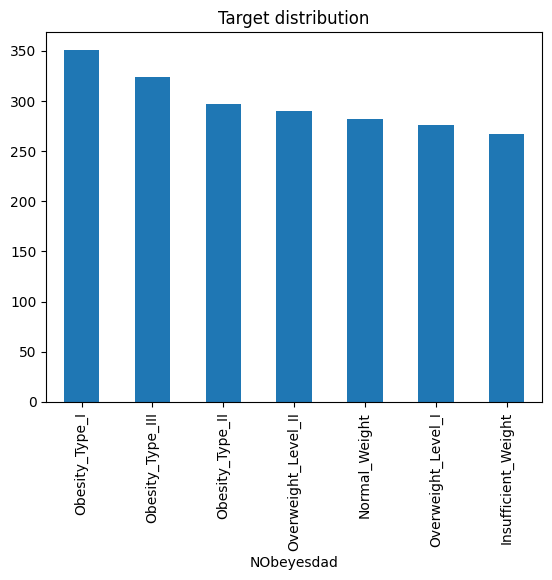

In [85]:
df.info()
print(df.describe().T)
print("Missing:\n", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

num = df.select_dtypes('number').columns
cat = df.select_dtypes('object').columns.drop('NObeyesdad')

# Target balance
df['NObeyesdad'].value_counts().plot(kind='bar', title='Target distribution'); plt.show()



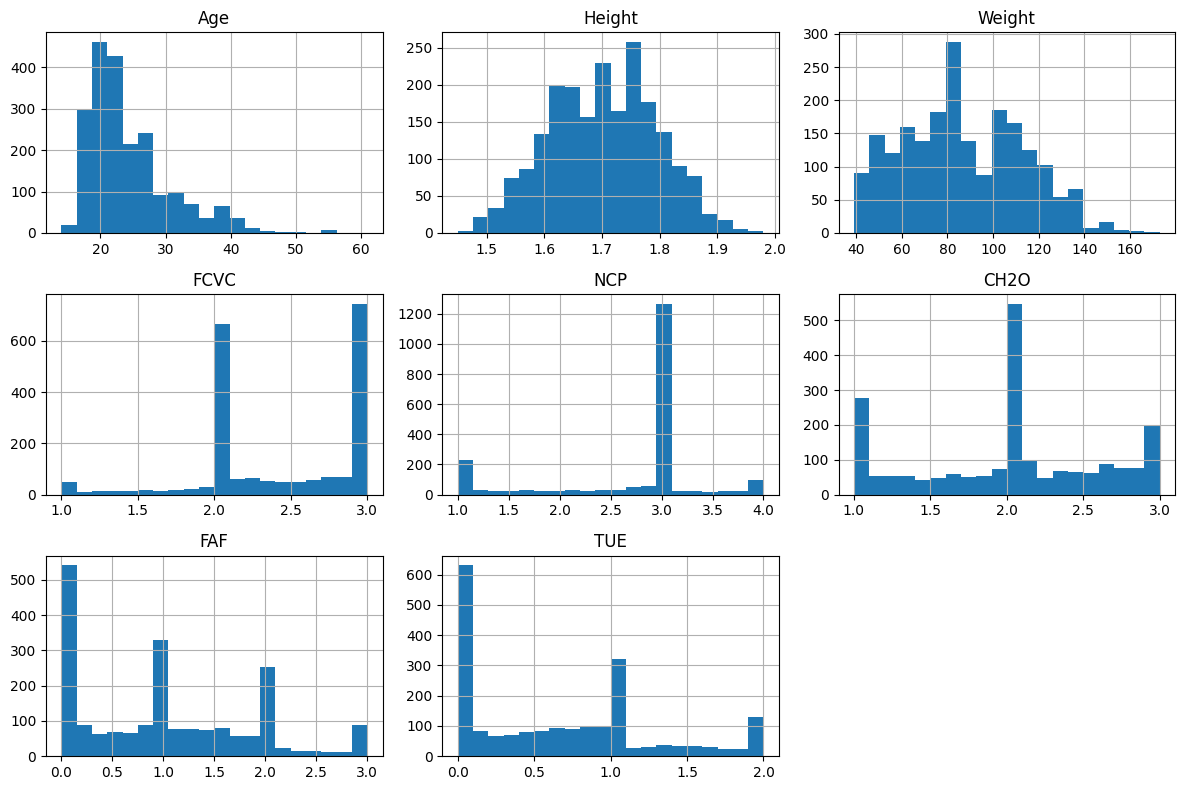

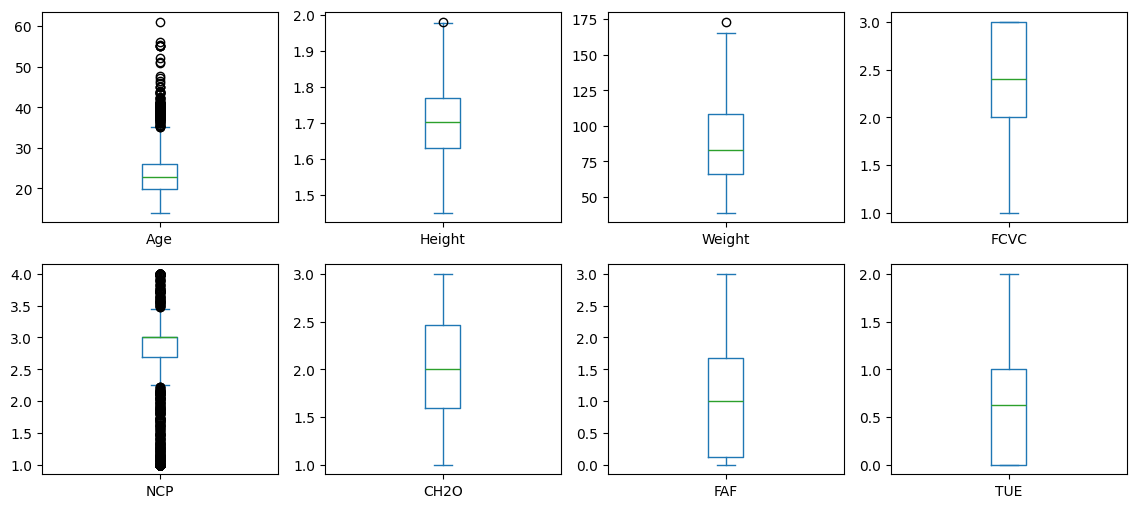

In [86]:
# Distributions + outliers
df[num].hist(figsize=(12,8), bins=20); plt.tight_layout(); plt.show()
df[num].plot(kind='box', subplots=True, layout=(2,4), figsize=(14,6)); plt.show()

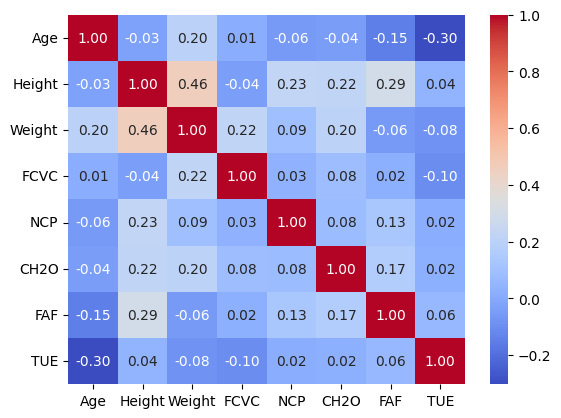

In [87]:
# Correlation
sns.heatmap(df[num].corr(), annot=True, cmap='coolwarm', fmt='.2f'); plt.show()

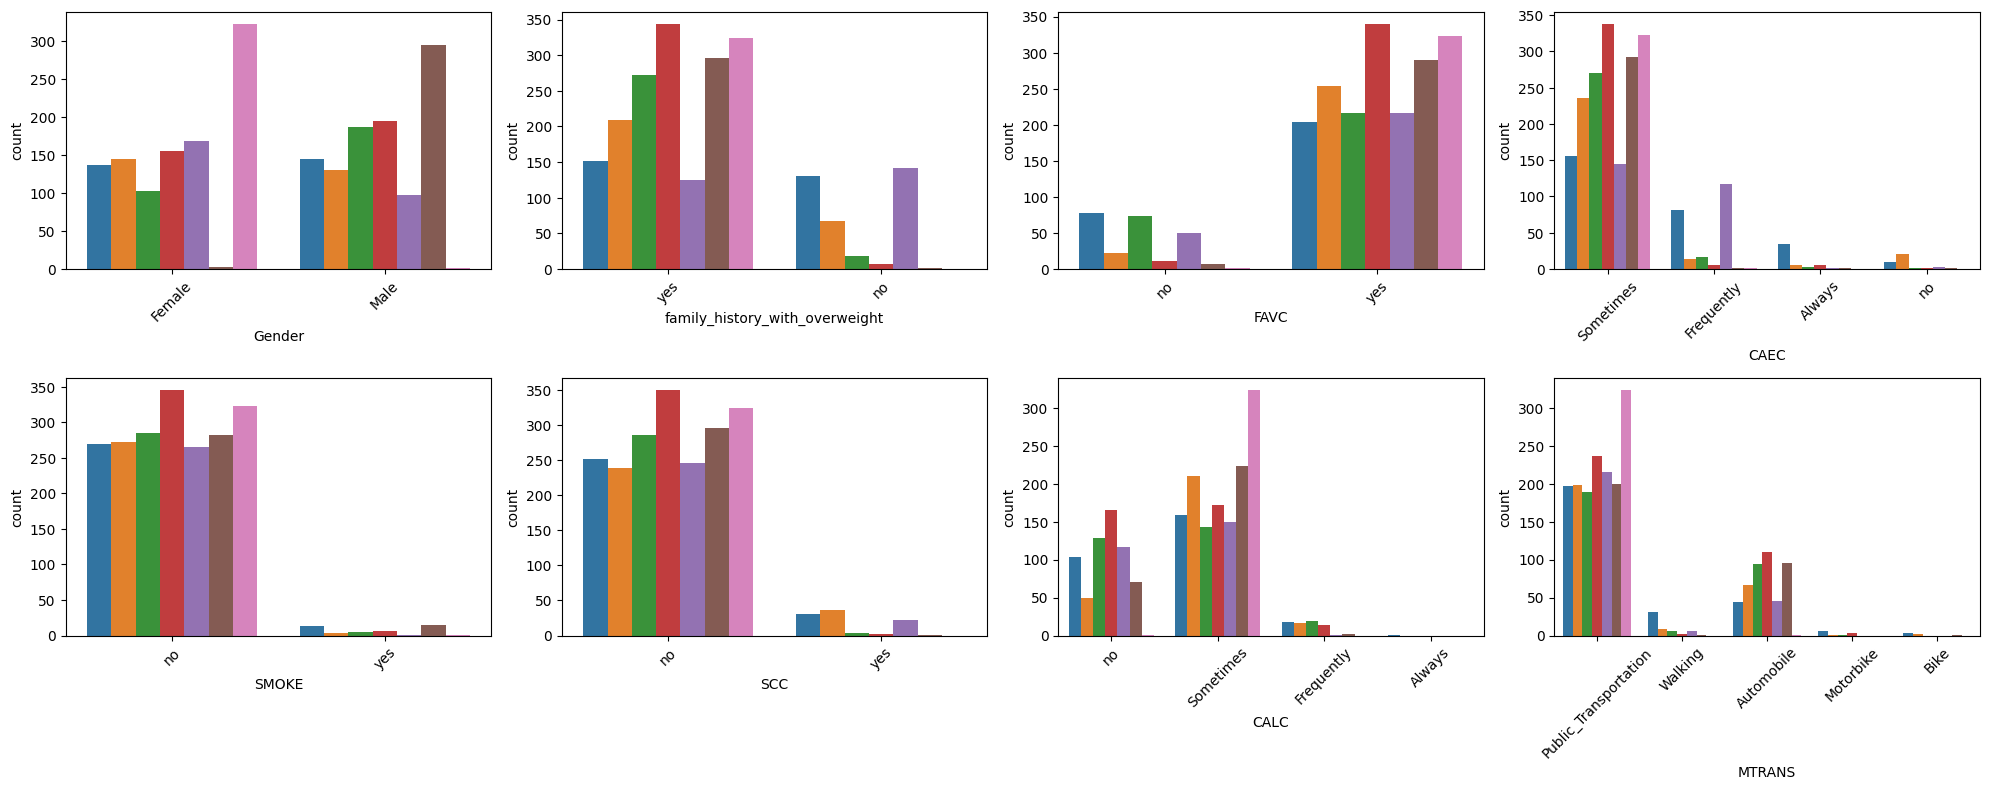

In [88]:
# Categorical vs target
fig, ax = plt.subplots(2,4, figsize=(20,8))
for a,c in zip(ax.ravel(), cat):
    sns.countplot(data=df, x=c, hue='NObeyesdad', ax=a, legend=False); a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

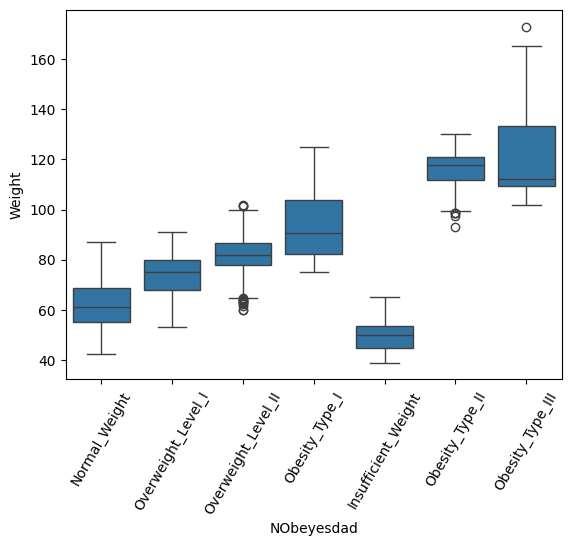

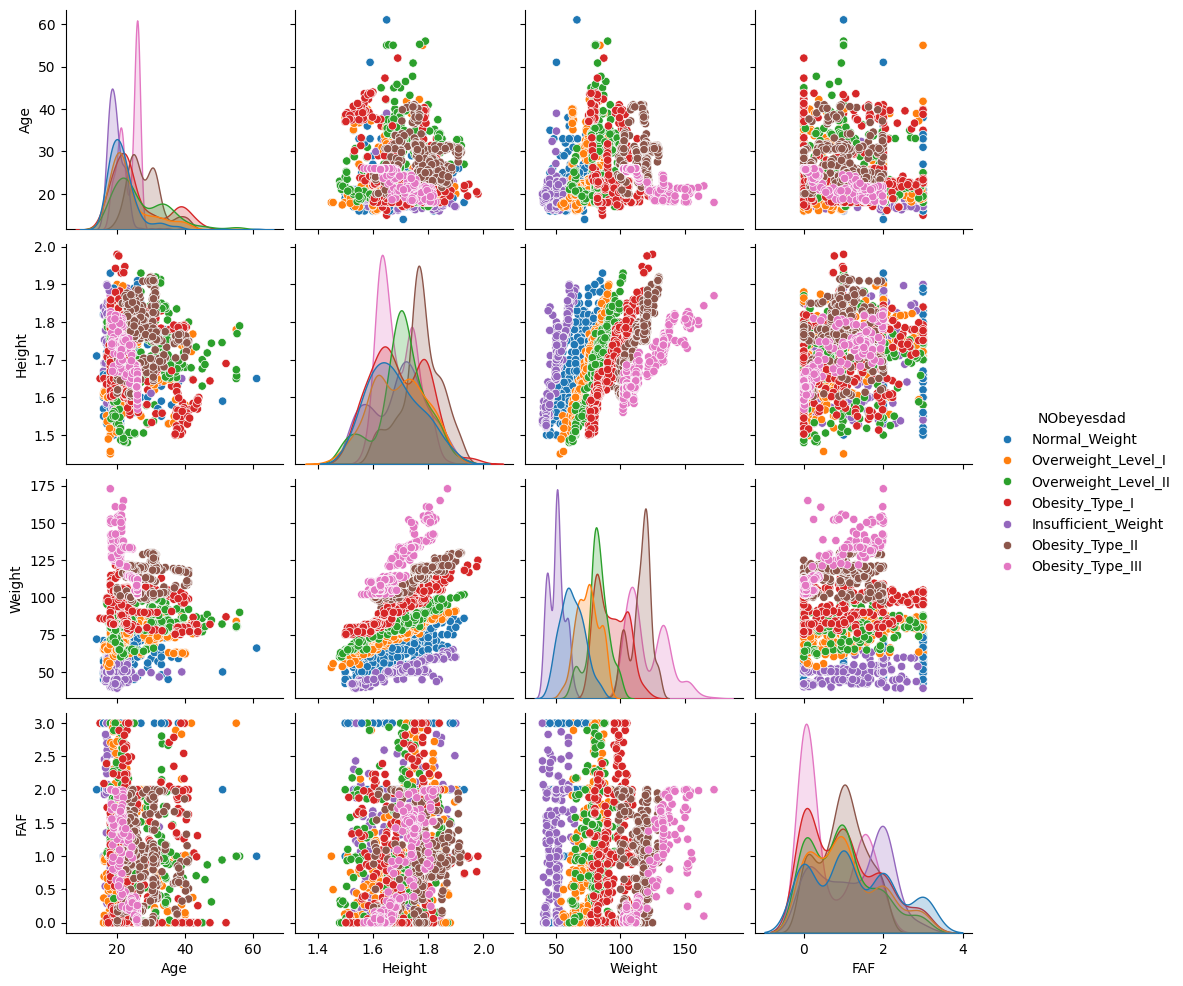

In [89]:
# Numeric vs target
sns.boxplot(data=df, x='NObeyesdad', y='Weight'); plt.xticks(rotation=60); plt.show()
sns.pairplot(df[['Age','Height','Weight','FAF','NObeyesdad']], hue='NObeyesdad'); plt.show()

### **Statistical EDA**

In [90]:
from scipy import stats
df = df.drop_duplicates().reset_index(drop=True)
num = df.select_dtypes('number').columns
cat = df.select_dtypes('object').columns.drop('NObeyesdad')

# Skewness, kurtosis, normality (D'Agostino, suits n>2000)
rows=[]
for c in num:
    stat,p = stats.normaltest(df[c])
    rows.append([c, df[c].skew(), df[c].kurt(), p, 'Normal' if p>0.05 else 'Not normal'])
print(pd.DataFrame(rows, columns=['Feature','Skew','Kurtosis','p-value','Verdict']).round(3))

# Outlier counts: IQR and Z-score
out=[]
for c in num:
    q1,q3 = df[c].quantile([.25,.75]); iqr=q3-q1
    iqr_n = ((df[c]<q1-1.5*iqr)|(df[c]>q3+1.5*iqr)).sum()
    z_n = (np.abs(stats.zscore(df[c]))>3).sum()
    out.append([c, iqr_n, z_n])
print(pd.DataFrame(out, columns=['Feature','IQR outliers','Z>3 outliers']))

# Categorical summary
for c in cat: print(df[c].value_counts(normalize=True).round(3), '\n')

  Feature   Skew  Kurtosis  p-value     Verdict
0     Age  1.514     2.768      0.0  Not normal
1  Height -0.025    -0.556      0.0  Not normal
2  Weight  0.242    -0.705      0.0  Not normal
3    FCVC -0.448    -0.624      0.0  Not normal
4     NCP -1.138     0.535      0.0  Not normal
5    CH2O -0.106    -0.864      0.0  Not normal
6     FAF  0.494    -0.638      0.0  Not normal
7     TUE  0.609    -0.554      0.0  Not normal
  Feature  IQR outliers  Z>3 outliers
0     Age           167            23
1  Height             1             0
2  Weight             1             1
3    FCVC             0             0
4     NCP           577             0
5    CH2O             0             0
6     FAF             0             0
7     TUE             0             0
Gender
Male      0.504
Female    0.496
Name: proportion, dtype: float64 

family_history_with_overweight
yes    0.825
no     0.175
Name: proportion, dtype: float64 

FAVC
yes    0.884
no     0.116
Name: proportion, dtype: floa

### **Visual Heavy**

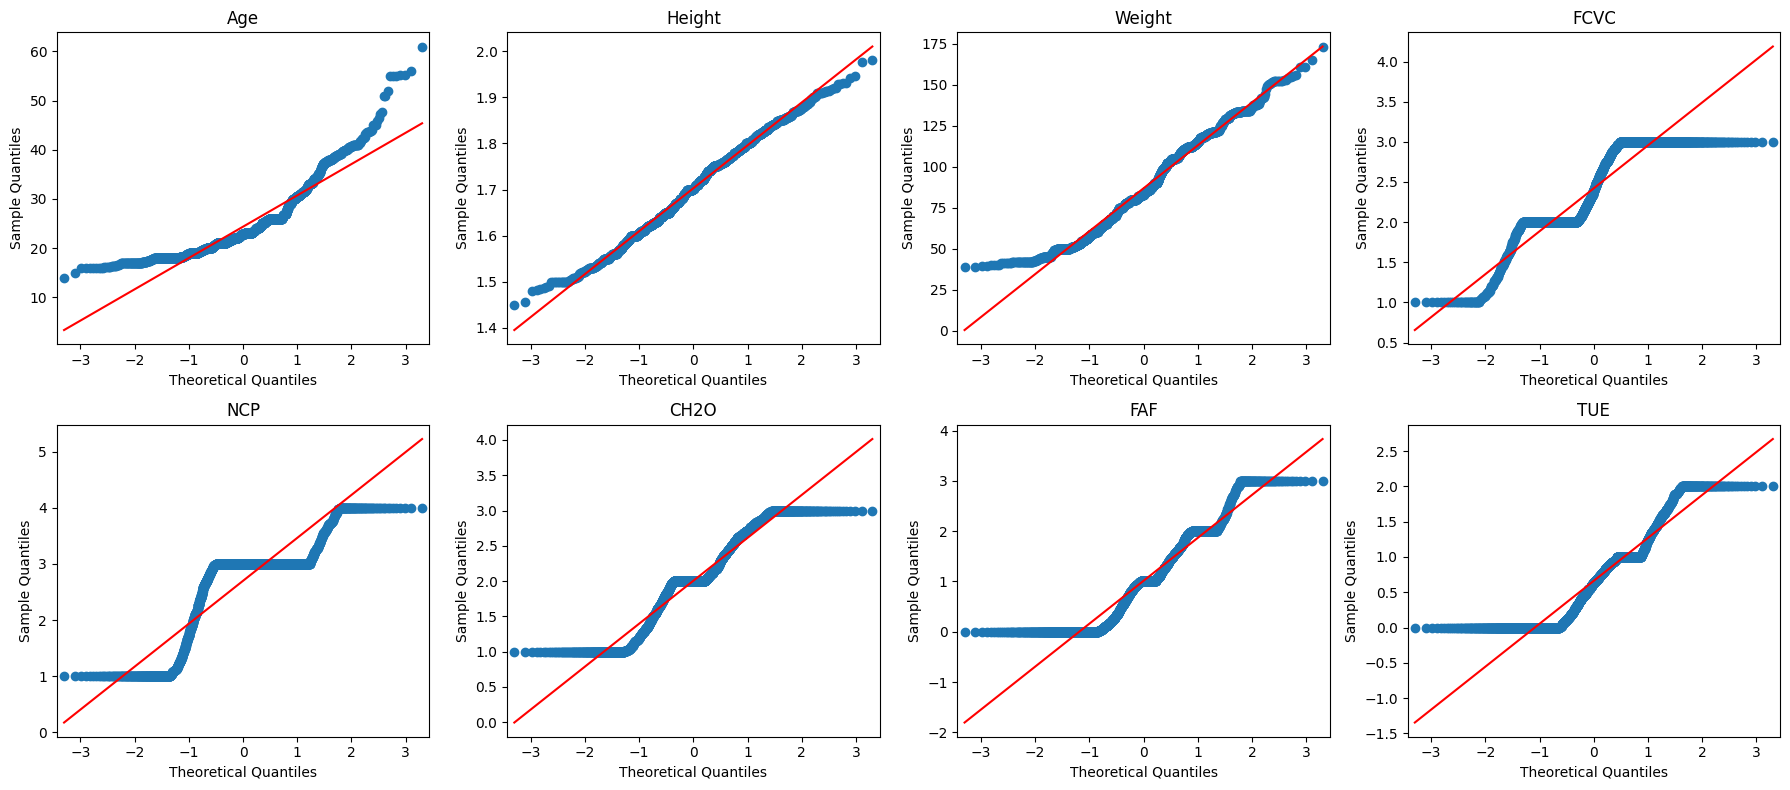

In [91]:
from statsmodels.graphics.gofplots import qqplot
order = ['Insufficient_Weight','Normal_Weight','Overweight_Level_I','Overweight_Level_II',
         'Obesity_Type_I','Obesity_Type_II','Obesity_Type_III']

# 1. Q-Q plots
fig,ax = plt.subplots(2,4, figsize=(18,8))
for a,c in zip(ax.ravel(), num): qqplot(df[c], line='s', ax=a); a.set_title(c)
plt.tight_layout(); plt.show()



/tmp/ipykernel_454/4025220982.py:3: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  for a,c in zip(ax.ravel(), num): sns.kdeplot(data=df, x=c, hue='NObeyesdad', ax=a, legend=False, common_norm=False)
/tmp/ipykernel_454/4025220982.py:3: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  for a,c in zip(ax.ravel(), num): sns.kdeplot(data=df, x=c, hue='NObeyesdad', ax=a, legend=False, common_norm=False)


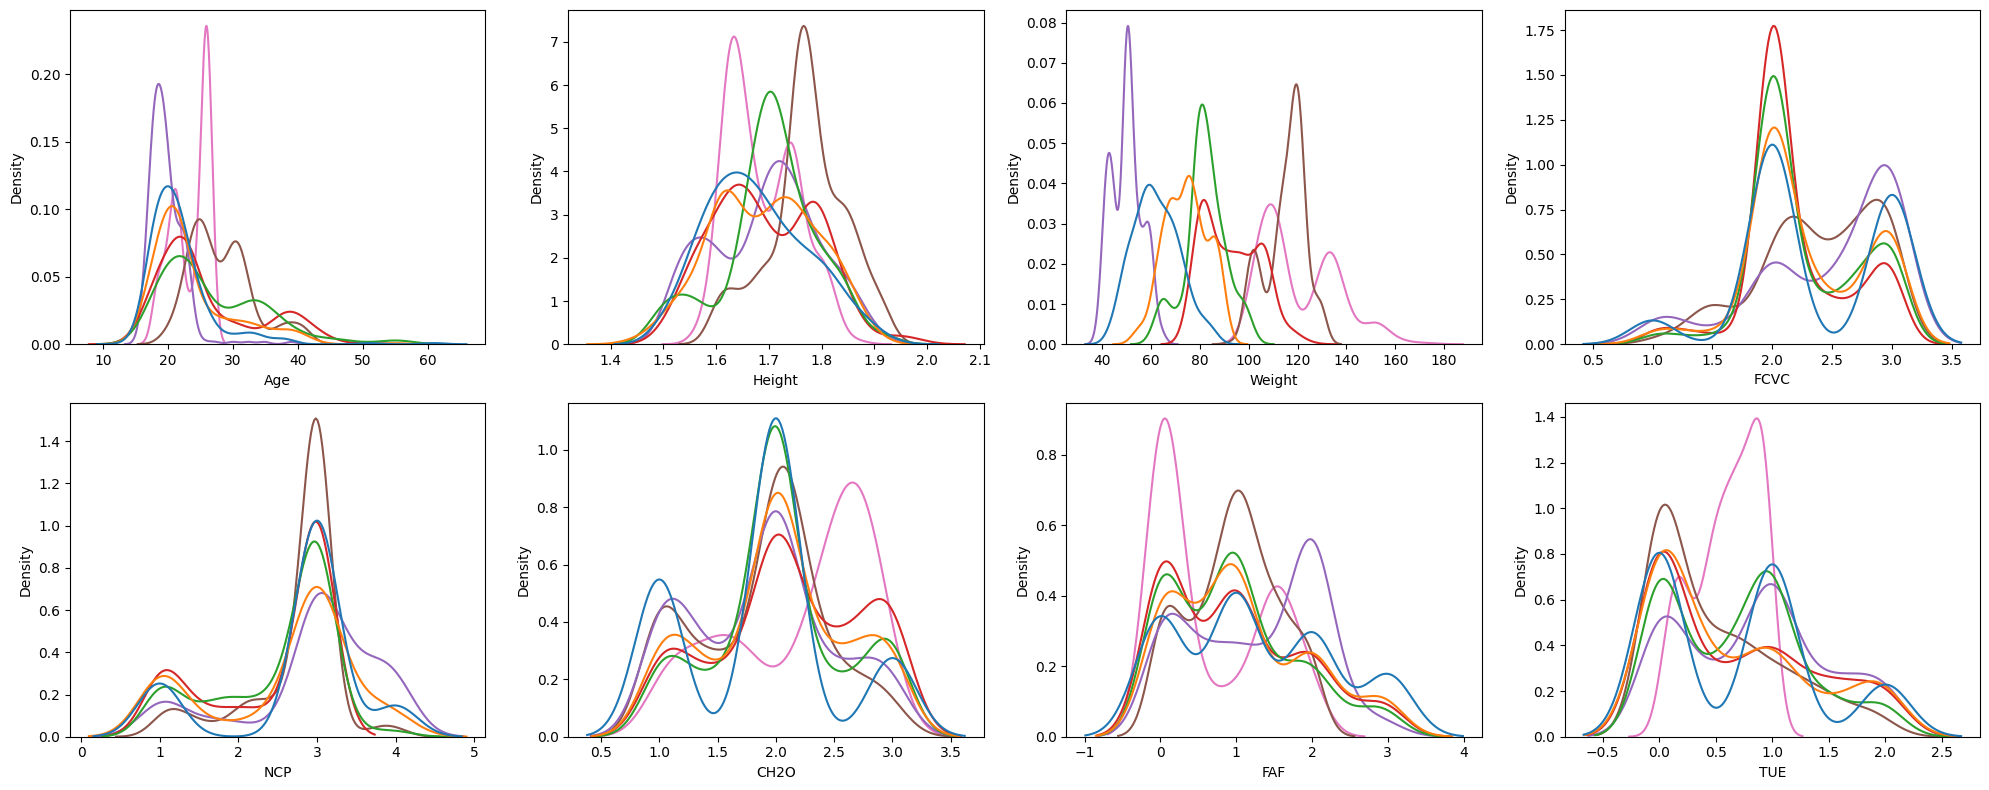

In [92]:
# 2. KDE of numeric features by class
fig,ax = plt.subplots(2,4, figsize=(20,8))
for a,c in zip(ax.ravel(), num): sns.kdeplot(data=df, x=c, hue='NObeyesdad', ax=a, legend=False, common_norm=False)
plt.tight_layout(); plt.show()


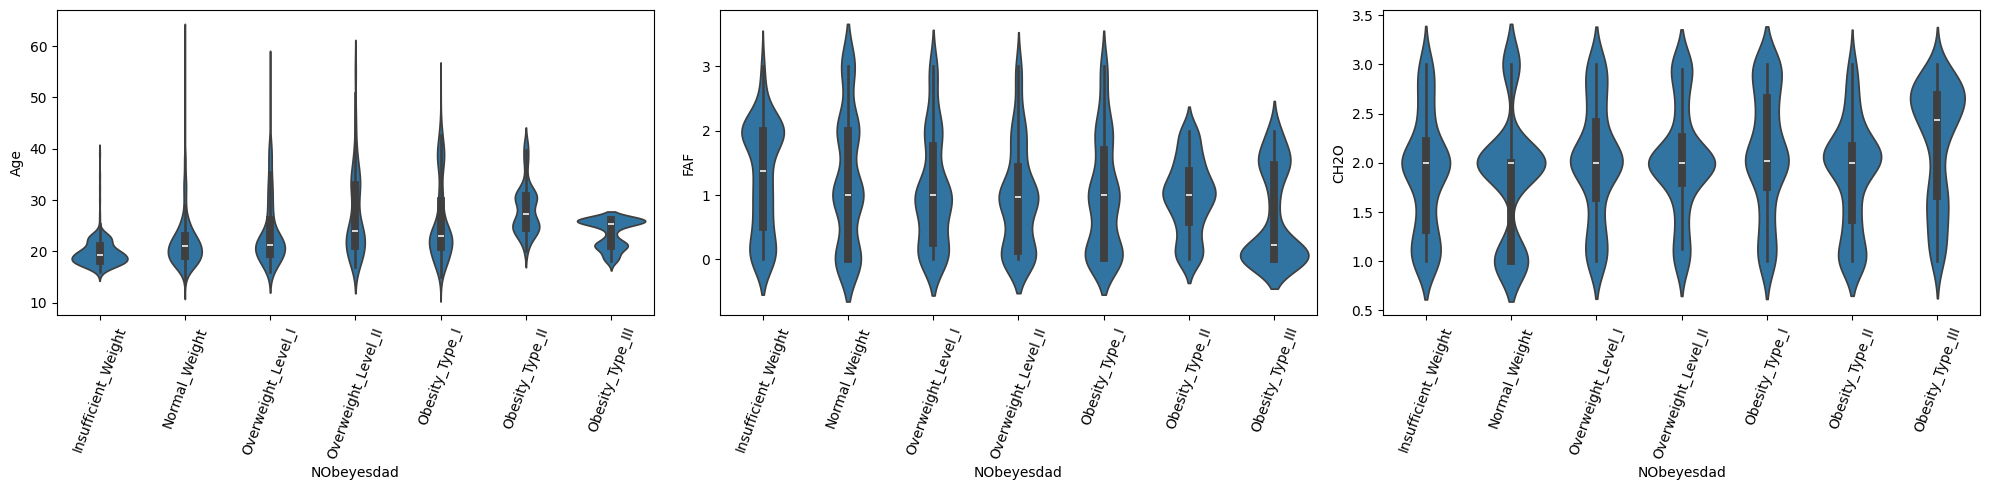

In [93]:
# 3. Violin plots
fig,ax = plt.subplots(1,3, figsize=(20,5))
for a,c in zip(ax, ['Age','FAF','CH2O']):
    sns.violinplot(data=df, x='NObeyesdad', y=c, order=order, ax=a); a.tick_params(axis='x', rotation=70)
plt.tight_layout(); plt.show()


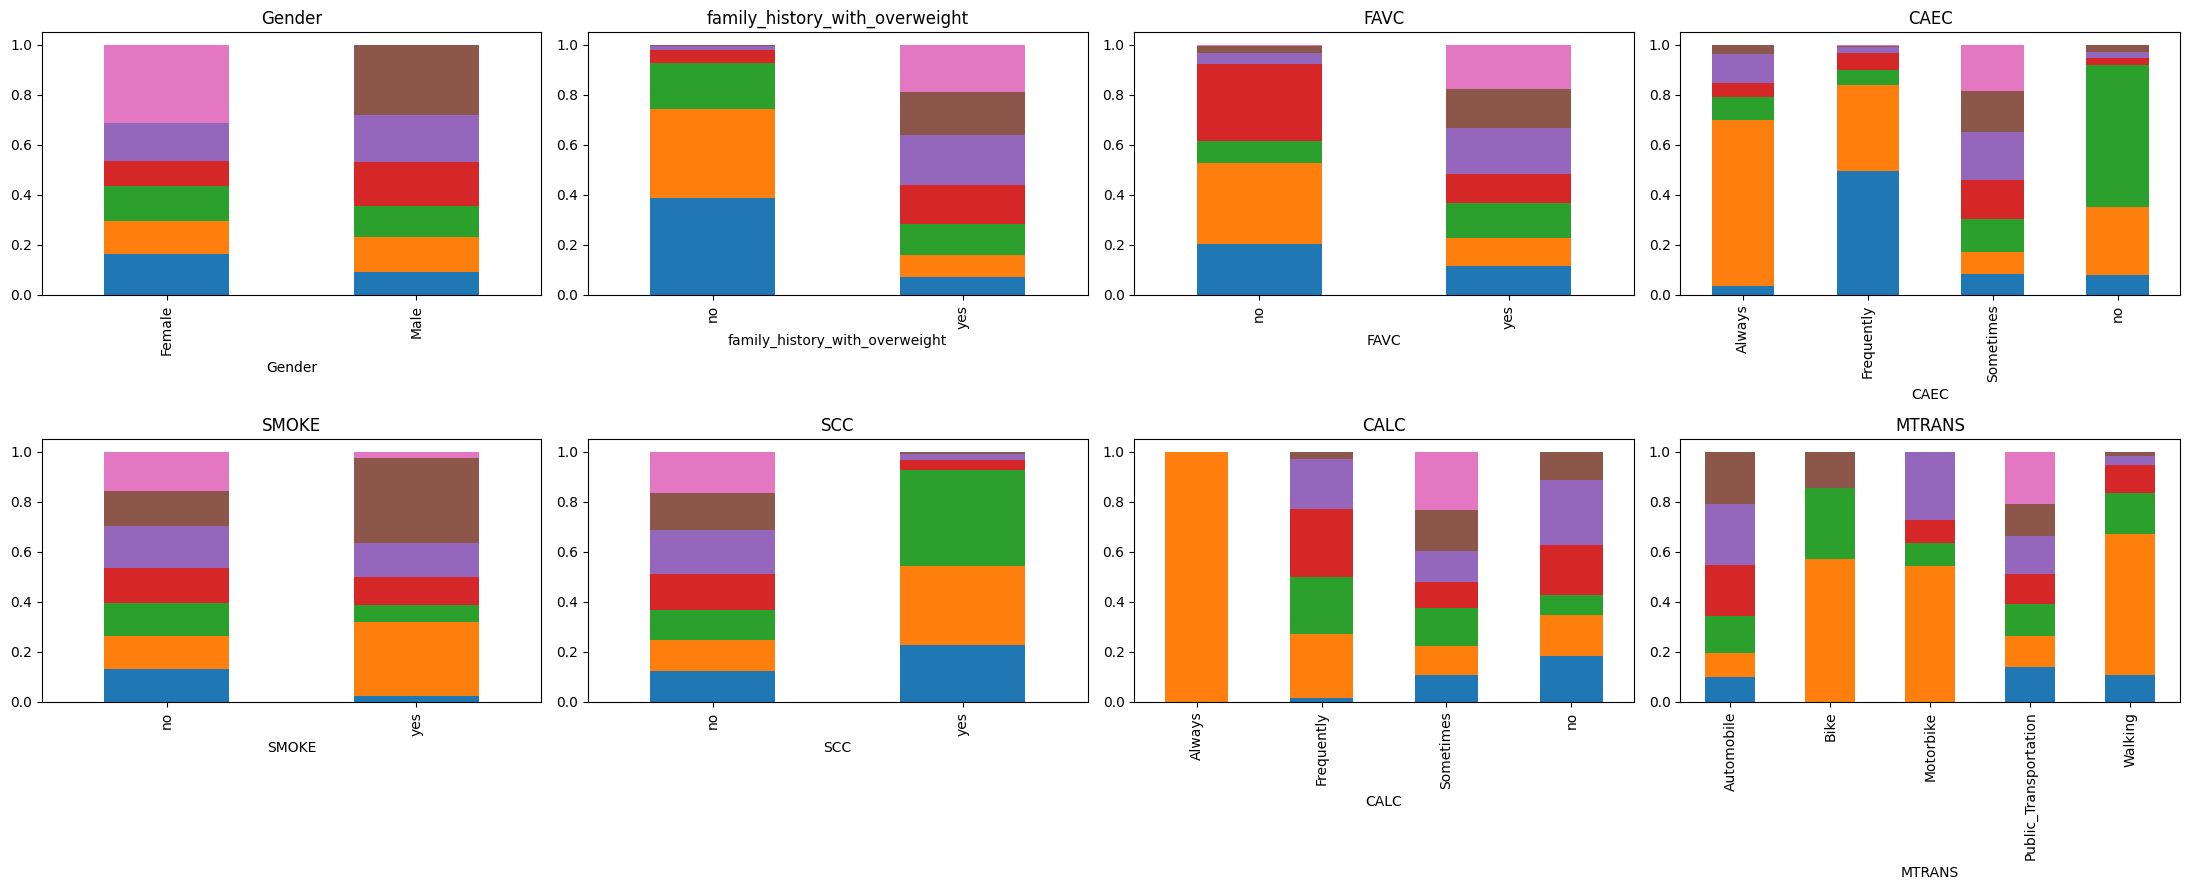

In [94]:
# 4. Stacked proportion bars for categoricals
fig,ax = plt.subplots(2,4, figsize=(22,9))
for a,c in zip(ax.ravel(), cat):
    pd.crosstab(df[c], df['NObeyesdad'], normalize='index')[order].plot(kind='bar', stacked=True, ax=a, legend=False)
    a.set_title(c)
plt.tight_layout(); plt.show()

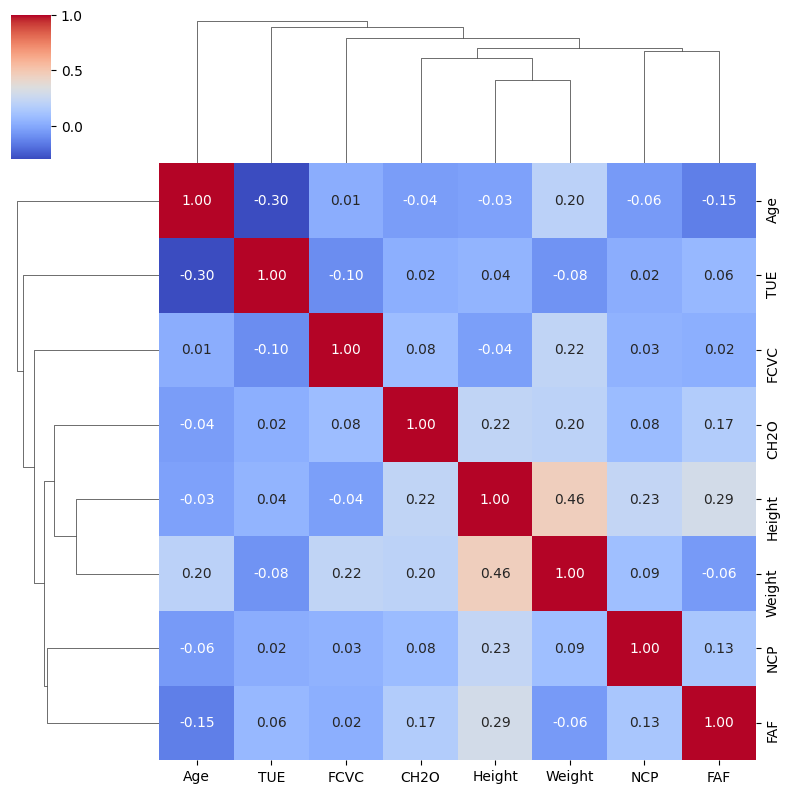

In [95]:
# 5. Clustered correlation + BMI scatter
sns.clustermap(df[num].corr(), annot=True, cmap='coolwarm', fmt='.2f', figsize=(8,8)); plt.show()



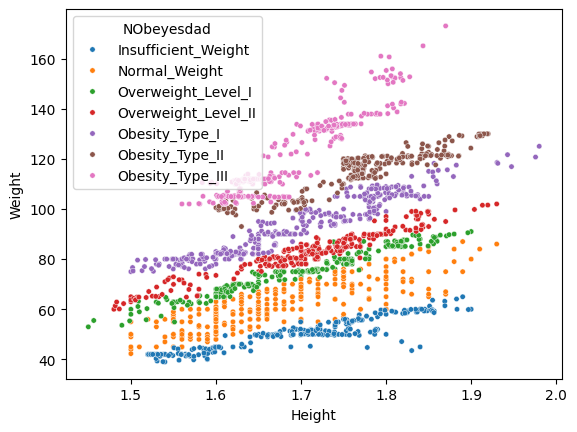

In [96]:
sns.scatterplot(data=df, x='Height', y='Weight', hue='NObeyesdad', hue_order=order, s=15); plt.show()

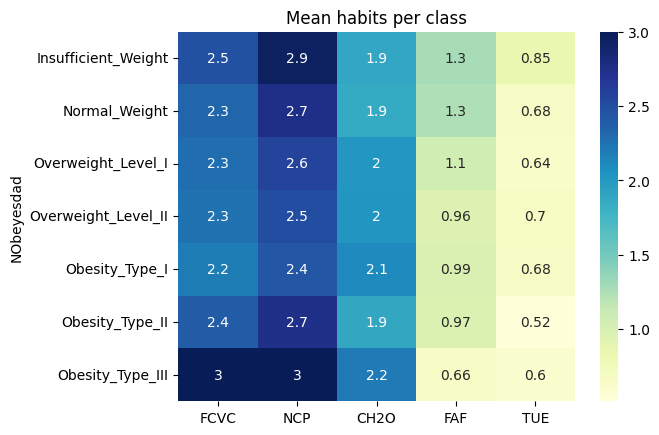

In [97]:
# 6. Mean heatmap of habits by class
sns.heatmap(df.groupby('NObeyesdad')[['FCVC','NCP','CH2O','FAF','TUE']].mean().loc[order],
            annot=True, cmap='YlGnBu'); plt.title('Mean habits per class'); plt.show()

### **Hypothesis-driven**

In [98]:
df['Obese'] = df['NObeyesdad'].str.contains('Obesity').astype(int)
alpha = 0.05

def chi(col):
    ct = pd.crosstab(df[col], df['Obese'])
    chi2,p,_,_ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2/(ct.values.sum()*(min(ct.shape)-1)))   # Cramér's V
    return p, v

results=[]
# H1: Physical activity (FAF) differs across obesity levels
H = stats.kruskal(*[g['FAF'] for _,g in df.groupby('NObeyesdad')])
results.append(['H1: FAF differs across classes', 'Kruskal-Wallis', H.pvalue, None])

# H2: Obese people exercise less than non-obese
a,b = df[df.Obese==1]['FAF'], df[df.Obese==0]['FAF']
results.append(['H2: Obese exercise less', 'Mann-Whitney (one-sided)',
                stats.mannwhitneyu(a,b,alternative='less').pvalue, None])

# H3: Family history associated with obesity
p,v = chi('family_history_with_overweight'); results.append(['H3: Family history ↔ obesity','Chi-square',p,v])
# H4: Frequent high-calorie food (FAVC) associated with obesity
p,v = chi('FAVC'); results.append(['H4: High-calorie food ↔ obesity','Chi-square',p,v])
# H5: Snacking between meals (CAEC) associated with obesity
p,v = chi('CAEC'); results.append(['H5: Snacking ↔ obesity','Chi-square',p,v])
# H6: Transport mode associated with obesity
p,v = chi('MTRANS'); results.append(['H6: Transport ↔ obesity','Chi-square',p,v])
# H7: Obese people are older
a,b = df[df.Obese==1]['Age'], df[df.Obese==0]['Age']
results.append(['H7: Obese are older','Mann-Whitney (one-sided)',
                stats.mannwhitneyu(a,b,alternative='greater').pvalue, None])
# H8: Weight vs FAF correlation
r,p = stats.spearmanr(df['Weight'], df['FAF']); results.append([f'H8: Weight~FAF (rho={r:.2f})','Spearman',p,None])

R = pd.DataFrame(results, columns=['Hypothesis','Test','p-value',"Cramér's V"])
R['Decision'] = np.where(R['p-value']<alpha/len(R), 'Reject H0 (Bonferroni)', 'Fail to reject')
print(R.round(4).to_string(index=False))

                     Hypothesis                     Test  p-value  Cramér's V               Decision
 H1: FAF differs across classes           Kruskal-Wallis   0.0000         NaN Reject H0 (Bonferroni)
        H2: Obese exercise less Mann-Whitney (one-sided)   0.0000         NaN Reject H0 (Bonferroni)
   H3: Family history ↔ obesity               Chi-square   0.0000      0.4084 Reject H0 (Bonferroni)
H4: High-calorie food ↔ obesity               Chi-square   0.0000      0.2805 Reject H0 (Bonferroni)
         H5: Snacking ↔ obesity               Chi-square   0.0000      0.3557 Reject H0 (Bonferroni)
        H6: Transport ↔ obesity               Chi-square   0.0000      0.1471 Reject H0 (Bonferroni)
            H7: Obese are older Mann-Whitney (one-sided)   0.0000         NaN Reject H0 (Bonferroni)
     H8: Weight~FAF (rho=-0.05)                 Spearman   0.0244         NaN         Fail to reject


## **Preprocessing**

In [99]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# ---- Task A: regression (target = Weight) ----
XA = pd.get_dummies(df.drop(columns=['Weight','NObeyesdad']), drop_first=True)
yA = df['Weight']
XA_tr, XA_te, yA_tr, yA_te = train_test_split(XA, yA, test_size=0.2, random_state=42)
sc = StandardScaler().fit(XA_tr)
XA_tr_s, XA_te_s = sc.transform(XA_tr), sc.transform(XA_te)

# ---- Task B: classification (target = obesity level) ----
XB = pd.get_dummies(df.drop(columns=['Height','Weight','NObeyesdad']), drop_first=True)
le = LabelEncoder(); yB = le.fit_transform(df['NObeyesdad'])
XB_tr, XB_te, yB_tr, yB_te = train_test_split(XB, yB, test_size=0.2, random_state=42, stratify=yB)
scB = StandardScaler().fit(XB_tr)
XB_tr_s, XB_te_s = scB.transform(XB_tr), scB.transform(XB_te)

## **Regularized regression**

In [100]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {'Linear':LinearRegression(), 'Ridge':Ridge(alpha=1),
          'Lasso':Lasso(alpha=0.1), 'ElasticNet':ElasticNet(alpha=0.1, l1_ratio=0.5)}
rows=[]
for n,m in models.items():
    m.fit(XA_tr_s, yA_tr); p = m.predict(XA_te_s)
    rows.append([n, mean_absolute_error(yA_te,p), mean_squared_error(yA_te,p),
                 np.sqrt(mean_squared_error(yA_te,p)), r2_score(yA_te,p)])
print(pd.DataFrame(rows, columns=['Model','MAE','MSE','RMSE','R2']).round(3))

# Which features did Lasso drop?
print(pd.Series(models['Lasso'].coef_, index=XA.columns).sort_values())

        Model    MAE      MSE    RMSE     R2
0      Linear  8.825  131.299  11.459  0.814
1       Ridge  8.823  131.268  11.457  0.814
2       Lasso  8.788  130.076  11.405  0.816
3  ElasticNet  8.748  130.388  11.419  0.815
CALC_no                               -2.314299
CAEC_Frequently                       -2.030727
Gender_Male                           -1.659612
FAF                                   -0.698873
FAVC_yes                              -0.598488
SMOKE_yes                             -0.311040
SCC_yes                               -0.065167
TUE                                   -0.000000
CALC_Frequently                       -0.000000
NCP                                   -0.000000
MTRANS_Walking                         0.271468
MTRANS_Bike                            0.282394
MTRANS_Motorbike                       0.338530
CALC_Sometimes                         0.348743
CH2O                                   0.357077
CAEC_Sometimes                         0.818764
CAEC_no

## **Binary Logistic regression  (Obese vs Not Obese)**

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       223
           1       1.00      1.00      1.00       195

    accuracy                           1.00       418
   macro avg       1.00      1.00      1.00       418
weighted avg       1.00      1.00      1.00       418

ROC-AUC: 1.0


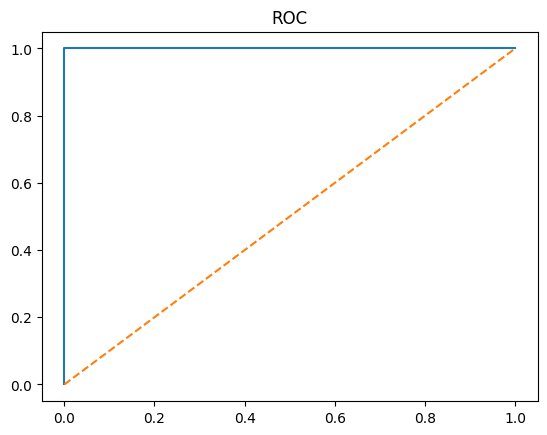

In [101]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, accuracy_score

obese_cls = [i for i,c in enumerate(le.classes_) if 'Obesity' in c]
yb_tr, yb_te = np.isin(yB_tr, obese_cls).astype(int), np.isin(yB_te, obese_cls).astype(int)

lr = LogisticRegression(max_iter=1000).fit(XB_tr_s, yb_tr)
prob = lr.predict_proba(XB_te_s)[:,1]
print(classification_report(yb_te, lr.predict(XB_te_s)))
print("ROC-AUC:", roc_auc_score(yb_te, prob))
fpr,tpr,_ = roc_curve(yb_te, prob); plt.plot(fpr,tpr); plt.plot([0,1],[0,1],'--'); plt.title('ROC'); plt.show()

## **MultiClass model comparison**

In [102]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

clfs = {
 'Logistic':(LogisticRegression(max_iter=2000), True),
 'DecisionTree':(DecisionTreeClassifier(max_depth=6, random_state=42), False),
 'RandomForest':(RandomForestClassifier(n_estimators=200, random_state=42), False),
 'GradBoost':(GradientBoostingClassifier(random_state=42), False),
 'XGBoost':(XGBClassifier(eval_metric='mlogloss', random_state=42), False),
 'LightGBM':(LGBMClassifier(random_state=42, verbose=-1), False),
 'KNN':(KNeighborsClassifier(n_neighbors=5), True),
 'SVM':(SVC(kernel='rbf'), True)}

res=[]; fitted={}
for n,(m,scaled) in clfs.items():
    Xtr,Xte = (XB_tr_s,XB_te_s) if scaled else (XB_tr,XB_te)
    m.fit(Xtr,yB_tr); p=m.predict(Xte); fitted[n]=(m,p)
    res.append([n, accuracy_score(yB_te,p), precision_score(yB_te,p,average='weighted'),
                recall_score(yB_te,p,average='weighted'), f1_score(yB_te,p,average='weighted')])
results = pd.DataFrame(res, columns=['Model','Acc','Prec','Recall','F1']).sort_values('F1',ascending=False)
print(results.round(3))

          Model    Acc   Prec  Recall     F1
5      LightGBM  0.902  0.905   0.902  0.903
2  RandomForest  0.900  0.902   0.900  0.900
4       XGBoost  0.892  0.893   0.892  0.893
3     GradBoost  0.880  0.881   0.880  0.881
7           SVM  0.830  0.841   0.830  0.833
6           KNN  0.821  0.821   0.821  0.818
0      Logistic  0.787  0.787   0.787  0.784
1  DecisionTree  0.746  0.759   0.746  0.749


## **visualization and Insights**

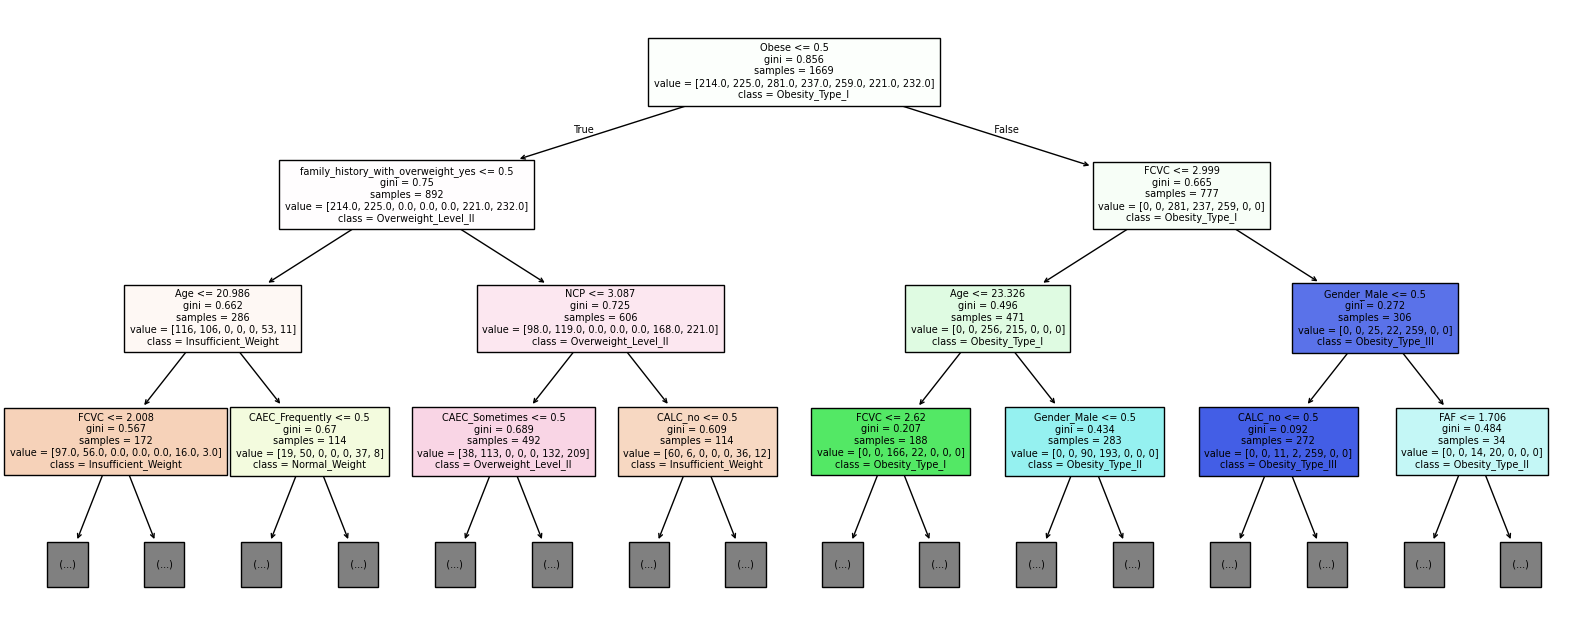

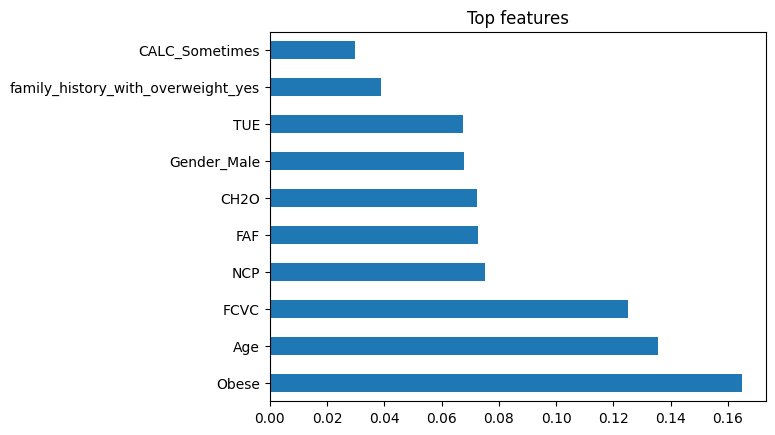

In [103]:
# Decision tree
plt.figure(figsize=(20,8))
plot_tree(fitted['DecisionTree'][0], feature_names=XB.columns, class_names=le.classes_, filled=True, max_depth=3, fontsize=7); plt.show()

# Feature importance (Random Forest)
pd.Series(fitted['RandomForest'][0].feature_importances_, index=XB.columns).nlargest(10).plot(kind='barh', title='Top features'); plt.show()



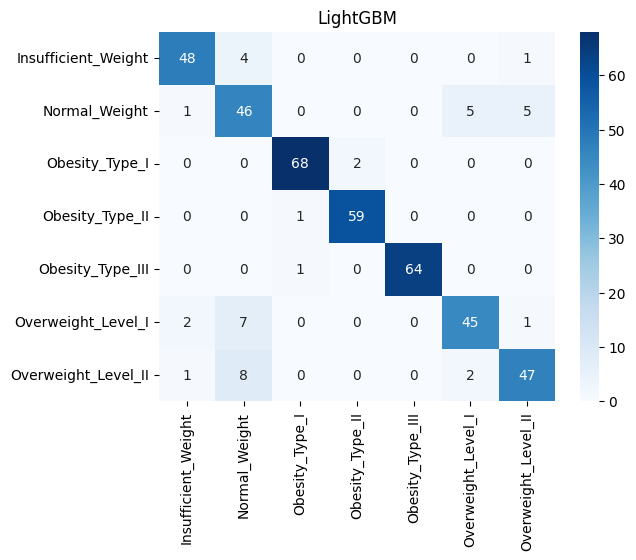

In [104]:
# Confusion matrix of the best model
best = results.iloc[0,0]
sns.heatmap(confusion_matrix(yB_te, fitted[best][1]), annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_, cmap='Blues')
plt.title(best); plt.show()